<a href="https://colab.research.google.com/github/mahashabdekedar/Quantum_Computing_Projects/blob/main/Deutch's_Alogrithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup

In [ ]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 68.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 78.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.8/120.8 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.2/224.2 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/54

In [ ]:
# Check qiskit version
import qiskit
print(qiskit.version.get_version_info())

2.5.2


In [ ]:
from qiskit import QuantumCircuit

# Create the Oracles
# Identity Oracle: f(0) = 0, f(1) = 1
qc1 = QuantumCircuit(2);
qc1.cx(0, 1);

gate_identity_oracle = qc1.to_gate()

print(qc1.draw())

# NOT Oracle
qc2 = QuantumCircuit(2)
qc2.x(0)
qc2.cx(0, 1)
qc2.x(0)

gate_not_oracle = qc2.to_gate()

# print(qc2.draw())

# Constant Zero Oracle
qc3 = QuantumCircuit(2)
qc3.id(0)

gate_constant_zero_oracle = qc3.to_gate()

# print(qc3.draw())

# Constant One Oracle
# Note to self: Surely there must be a better way to do this
qc4 = QuantumCircuit(2)
qc4.cx(0, 1)
qc4.x(0)
qc4.cx(0, 1)
qc4.x(0)

gate_constant_one_oracle = qc4.to_gate()

# print(qc4.draw())

          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘


In [ ]:
# Uncomment an oracle
# oracle = gate_identity_oracle
oracle = gate_not_oracle
# oracle = gate_constant_zero_oracle
# oracle = gate_constant_one_oracle

deutsch = QuantumCircuit(2, 1)
deutsch.h(0)
deutsch.x(1)
deutsch.h(1)
deutsch.append(oracle, [0, 1])
deutsch.h(0)
deutsch.measure(0, 0);

print(deutsch.draw())

     ┌───┐     ┌─────────────┐┌───┐┌─┐
q_0: ┤ H ├─────┤0            ├┤ H ├┤M├
     ├───┤┌───┐│  circuit-99 │└───┘└╥┘
q_1: ┤ X ├┤ H ├┤1            ├──────╫─
     └───┘└───┘└─────────────┘      ║ 
c: 1/═══════════════════════════════╩═
                                    0 


In [ ]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler, QiskitRuntimeService

# Syntax for first saving your token.  Delete these lines after saving your credentials.
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="EIFU7lnEfs6LbdeY9X9Zrr5tMODtEJPHOAXVeZf6jNu7",
    overwrite=True,
    set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# Load saved credentials
service = QiskitRuntimeService()

# Use the least busy backend, or uncomment the loading of a specific backend like "ibm_fez".
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
# backend = service.backend("ibm_fez")
print(backend.name)

qiskit_runtime_service.__init__:WARNING:2026-08-24 17:10:29,075: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Test Instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.__init__:WARNING:2026-08-24 17:10:31,411: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Test Instance. If you need a specific instance set it explicitly either by using a saved account with a saved default insta

ibm_kingston


In [ ]:
# Pasted from build and run your first quantum program
def run_circuit_and_get_counts(circuit, backend, shots=1000):
    """
    Runs a quantum circuit on a specified backend and returns the measurement counts.

    Args:
        circuit (QuantumCircuit): The quantum circuit to run.
        backend: The Qiskit backend (real device or simulator).
        shots (int): The number of shots to run the circuit.

    Returns:
        dict: A dictionary of measurement counts.
    """
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(circuit)

    sampler = Sampler(mode=backend)

    job = sampler.run([isa_circuit], shots=shots)
    result = job.result()

    return result[0].data.c.get_counts()

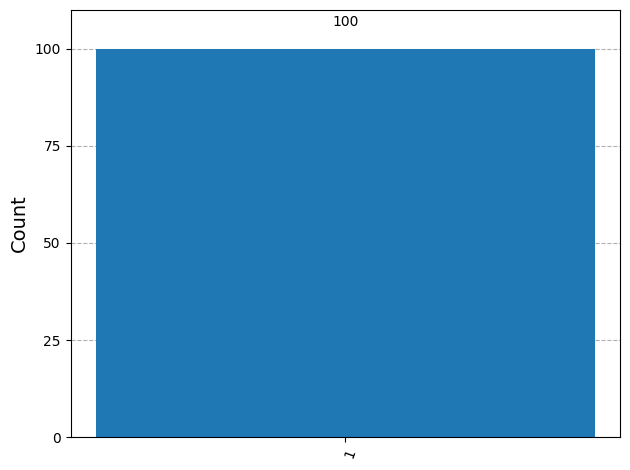

In [ ]:
from qiskit_aer import AerSimulator
backend = AerSimulator()
counts = run_circuit_and_get_counts(deutsch, backend, shots=100)

plot_histogram(counts)